# ST597 Final Project

## Chicago Dataset

API Link: https://dev.socrata.com/foundry/data.cityofchicago.org/85ca-t3if

### Test Load

In [1]:
#!/usr/bin/env python

# Make sure to install these packages before running:
# pip install pandas sodapy

import pandas as pd
from sodapy import Socrata

# Connect to the City of Chicago Open Data portal
client = Socrata("data.cityofchicago.org", None)

# Query the first 2,000 records from the Traffic Crashes dataset
dataset_id = "85ca-t3if"
results = client.get(dataset_id, limit=2000)

# Convert API response to a pandas DataFrame
df = pd.DataFrame.from_records(results)

# Confirmation & Verification
if len(df) == 2000:
    print(f"✅ Success! Retrieved exactly {len(df)} records.")
else:
    print(f"⚠️ Retrieved {len(df)} records.")

print(f"DataFrame dimensions: {df.shape[0]} rows x {df.shape[1]} columns\n")

# Display sample columns from the first few rows to verify contents
preview_cols = ["crash_record_id", "crash_date", "posted_speed_limit", "weather_condition"]
existing_cols = [col for col in preview_cols if col in df.columns]

print("Data Preview:")
print(df[existing_cols].head())

✅ Success! Retrieved exactly 2000 records.
DataFrame dimensions: 2000 rows x 50 columns

Data Preview:
                                     crash_record_id               crash_date  \
0  000d36adce8b4b793e9d0c5cd09dfed2e71309972d3437...  2026-08-20T13:29:00.000   
1  00cf9d4df2f160489077e6e8099032c366fe1da9a5be9a...  2026-09-12T14:10:00.000   
2  419e0f4348b4274d902d84bd7aa58f5fa9c10820b77abc...  2026-05-19T23:15:00.000   
3  1471094d2f2a497653584d887ed73cddcdfaa35fd02b20...  2026-05-20T07:51:00.000   
4  1c99690e19bd557cc6ad0674668dc492ab979c4e63a279...  2026-05-20T02:00:00.000   

  posted_speed_limit weather_condition  
0                 30             CLEAR  
1                 30             CLEAR  
2                 45             CLEAR  
3                 30             CLEAR  
4                 30             CLEAR  


## Application 10/19

### Response Distribution

Fetching crash counts from Chicago Open Data API...

=== Response Variable Distribution (2023-2025) ===
Other Crashes (< 2): 318,220 (95.87%)
Multiple Injuries (>= 2): 13,707 (4.13%)
Total Crashes Analyzed: 331,927



/var/folders/v4/tn3ck93937s38sfld66jv9780000gn/T/ipykernel_2484/1184569026.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  bars = sns.barplot(


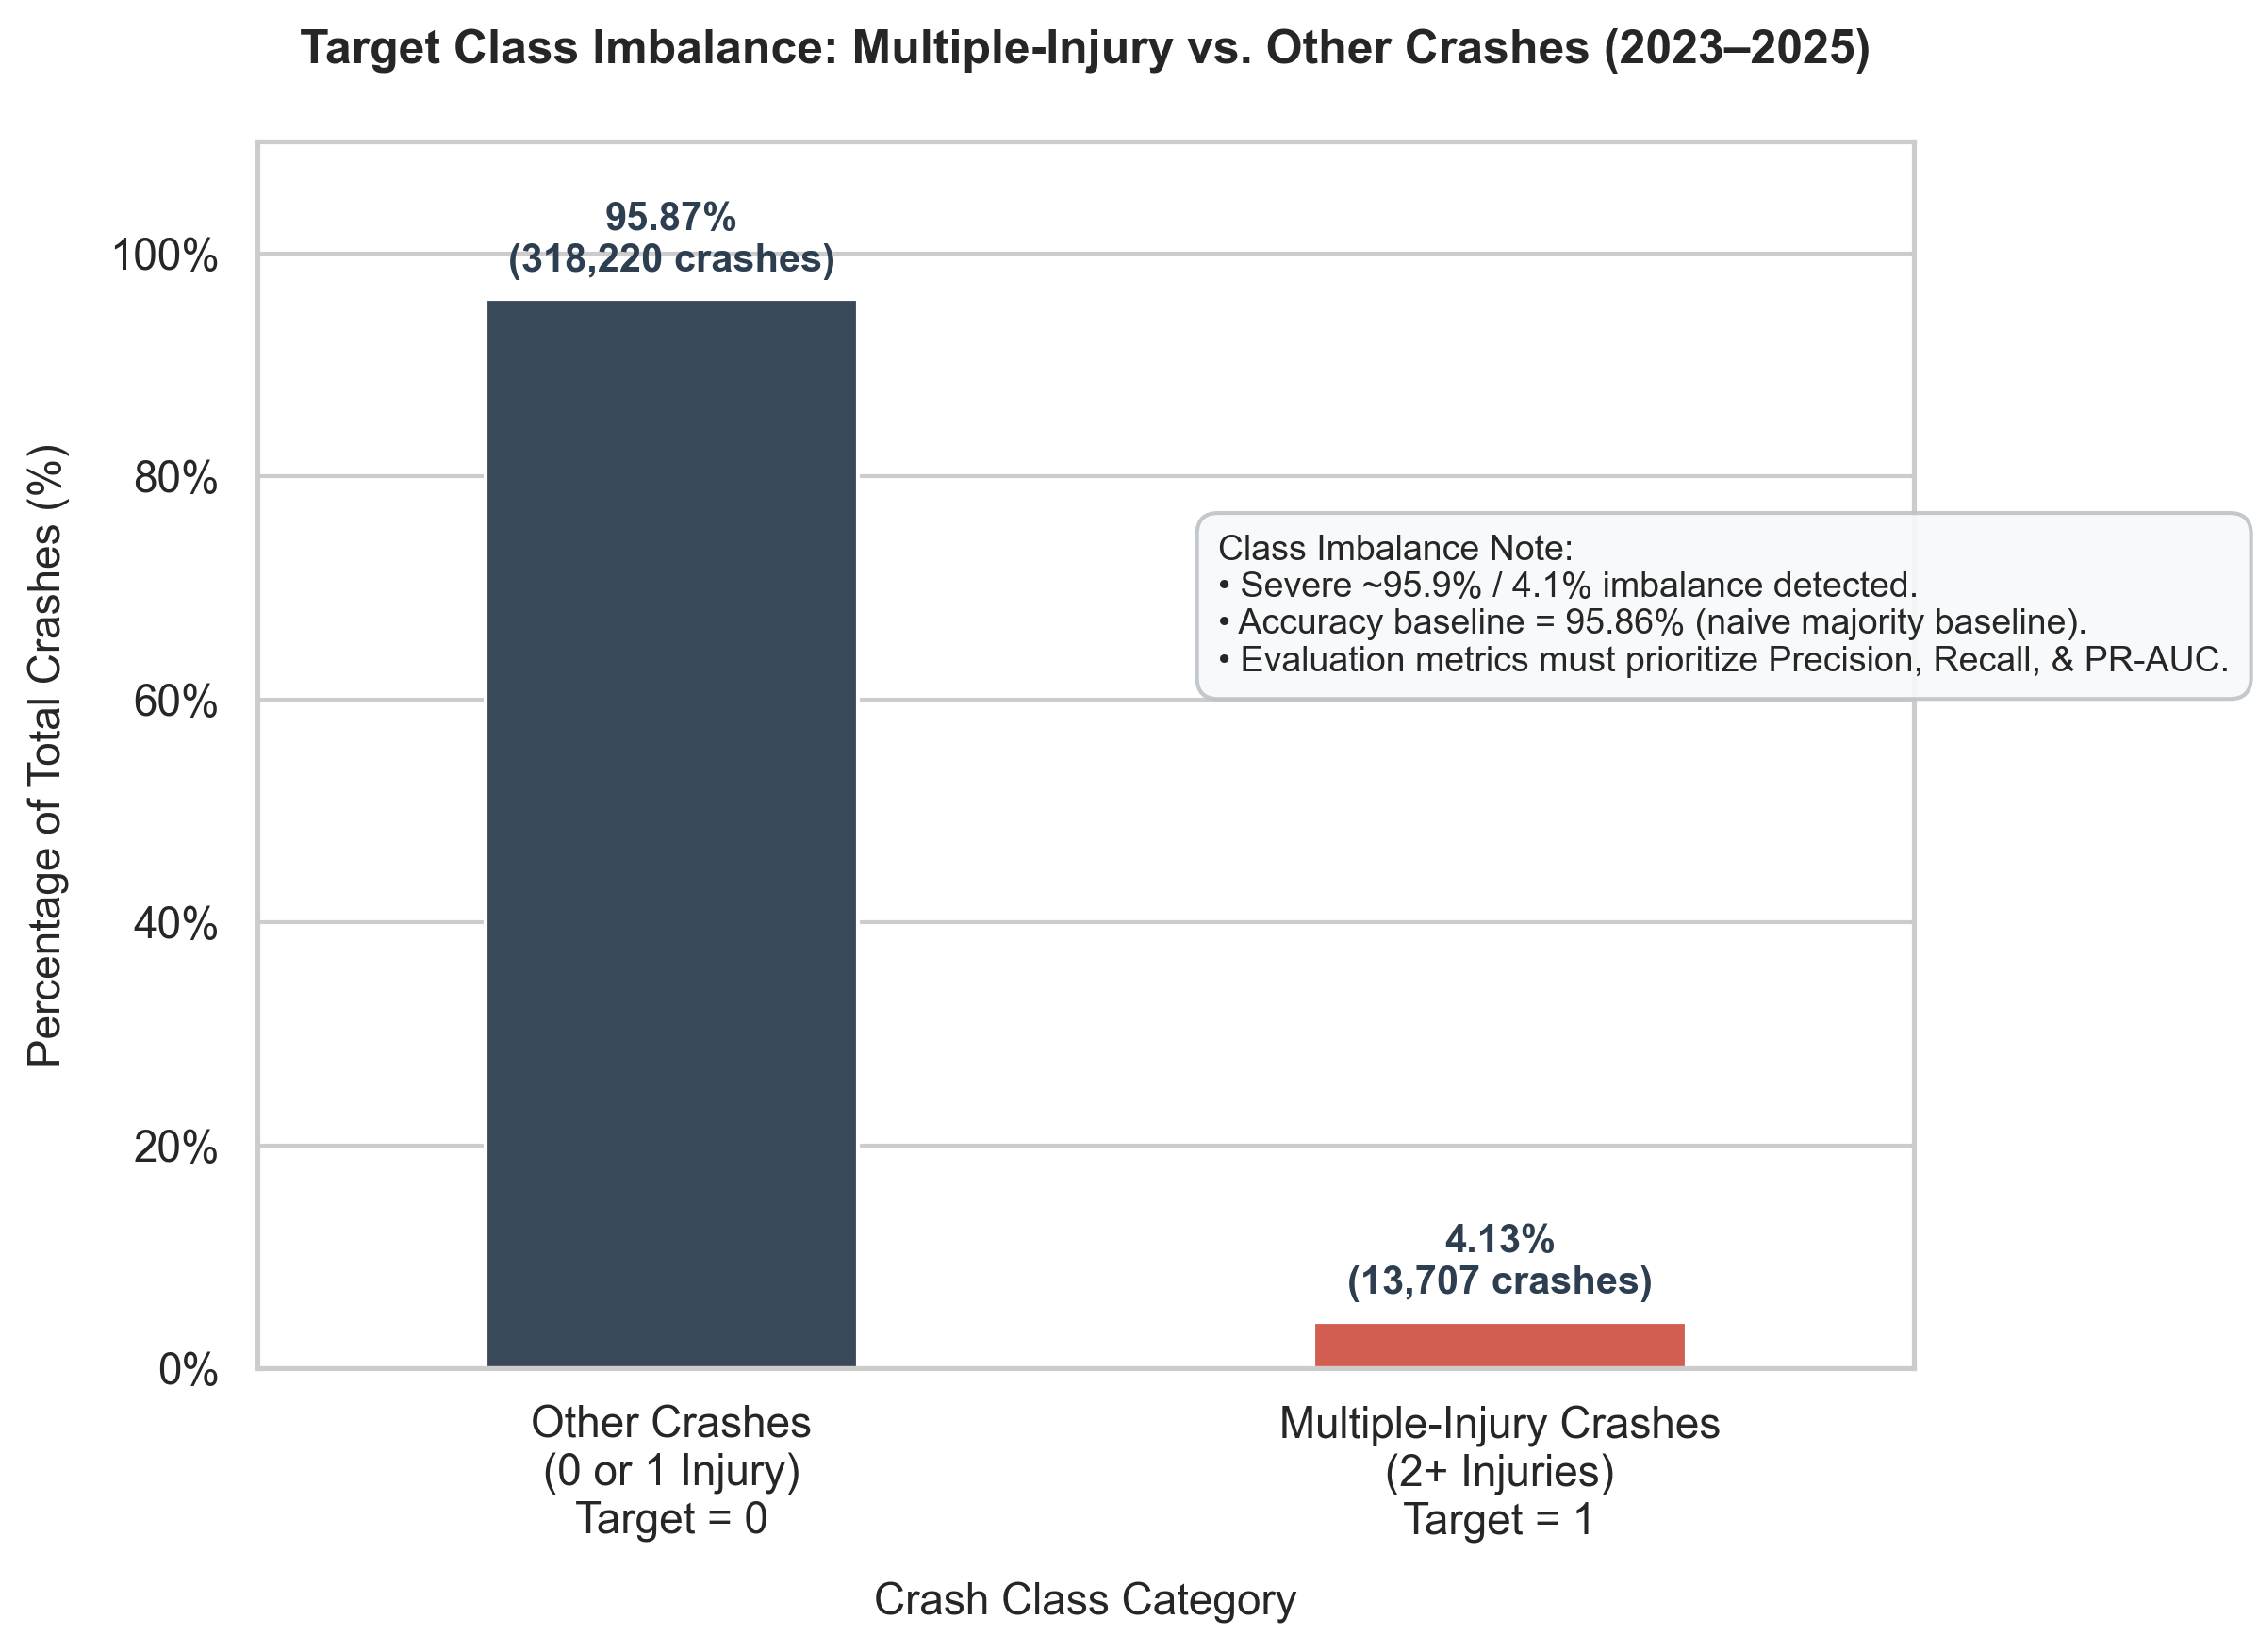

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import requests
import seaborn as sns


def fetch_and_plot_response_distribution():
    endpoint = "https://data.cityofchicago.org/resource/85ca-t3if.json"

    # Standard SoQL parameter queries (compatible with Socrata API)
    # Query 1: Multiple-Injury Crashes (Target = 1)
    params_multiple = {
        "$select": "count(crash_record_id) AS count",
        "$where": "crash_date >= '2023-01-01T00:00:00' AND crash_date <= '2025-12-31T23:59:59' AND injuries_total >= 2",
    }

    # Query 2: Other Crashes (Target = 0)
    params_other = {
        "$select": "count(crash_record_id) AS count",
        "$where": "crash_date >= '2023-01-01T00:00:00' AND crash_date <= '2025-12-31T23:59:59' AND (injuries_total < 2 OR injuries_total IS NULL)",
    }

    print("Fetching crash counts from Chicago Open Data API...")
    res_mult = requests.get(endpoint, params=params_multiple)
    res_mult.raise_for_status()
    count_multiple = int(res_mult.json()[0]["count"])

    res_other = requests.get(endpoint, params=params_other)
    res_other.raise_for_status()
    count_other = int(res_other.json()[0]["count"])

    # Construct summary DataFrame
    df = pd.DataFrame([
        {
            "crash_category": "Other Crashes (< 2)",
            "category_label": "Other Crashes\n(0 or 1 Injury)\nTarget = 0",
            "count": count_other,
        },
        {
            "crash_category": "Multiple Injuries (>= 2)",
            "category_label": "Multiple-Injury Crashes\n(2+ Injuries)\nTarget = 1",
            "count": count_multiple,
        },
    ])

    # Calculate percentage distribution
    total_crashes = df["count"].sum()
    df["percentage"] = (df["count"] / total_crashes) * 100

    # Print summary to console
    print("\n=== Response Variable Distribution (2023-2025) ===")
    for _, row in df.iterrows():
        print(
            f"{row['crash_category']}: {row['count']:,} ({row['percentage']:.2f}%)"
        )
    print(f"Total Crashes Analyzed: {total_crashes:,}\n")

    # Plotting Configuration
    sns.set_theme(style="whitegrid")
    fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

    colors = ["#34495e", "#e74c3c"]

    bars = sns.barplot(
        data=df,
        x="category_label",
        y="percentage",
        palette=colors,
        ax=ax,
        width=0.45,
    )

    # Annotate bars with exact percentages and raw counts
    for bar, (_, row) in zip(bars.patches, df.iterrows()):
        height = bar.get_height()
        count_val = row["count"]
        ax.annotate(
            f"{height:.2f}%\n({count_val:,} crashes)",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
            color="#2c3e50",
        )

    # Styling labels
    ax.set_title(
        "Target Class Imbalance: Multiple-Injury vs. Other Crashes (2023–2025)",
        fontsize=12,
        fontweight="bold",
        pad=20,
    )
    ax.set_xlabel("Crash Class Category", fontsize=11, labelpad=10)
    ax.set_ylabel("Percentage of Total Crashes (%)", fontsize=11, labelpad=10)
    ax.set_ylim(0, 110)
    ax.yaxis.set_major_formatter("{x:.0f}%")

    # Annotation box
    text_box_str = (
        "Class Imbalance Note:\n"
        "• Severe ~95.9% / 4.1% imbalance detected.\n"
        "• Accuracy baseline = 95.86% (naive majority baseline).\n"
        "• Evaluation metrics must prioritize Precision, Recall, & PR-AUC."
    )
    ax.text(
        0.58,
        0.68,
        text_box_str,
        transform=ax.transAxes,
        fontsize=9,
        verticalalignment="top",
        bbox=dict(
            boxstyle="round,pad=0.6",
            facecolor="#f8f9fa",
            edgecolor="#bdc3c7",
            alpha=0.9,
        ),
    )

    plt.tight_layout()
    plt.savefig(
        "response_variable_distribution.png", dpi=300, bbox_inches="tight"
    )
    plt.show()


if __name__ == "__main__":
    fetch_and_plot_response_distribution()

In [6]:
import numpy as np
import pandas as pd
import requests

# 1. API Configuration & Column Extraction
ENDPOINT = "https://data.cityofchicago.org/resource/85ca-t3if.json"

# Candidate predictors + metadata columns
PREDICTOR_COLS = [
    "posted_speed_limit",
    "weather_condition",
    "lighting_condition",
    "roadway_surface_cond",
    "traffic_control_device",
    "device_condition",
    "trafficway_type",
    "alignment",
    "road_defect",
    "intersection_related_i",
    "lane_cnt",
    "street_direction",
    "first_crash_type",
    "work_zone_i",
    "work_zone_type",
    "workers_present_i",
]

METADATA_COLS = ["crash_record_id", "crash_date", "street_name", "location"]

TARGET_SOURCE_COL = "injuries_total"

LEAKAGE_COLS_TO_EXCLUDE = [
    "crash_type",
    "most_severe_injury",
    "injuries_fatal",
    "injuries_incapacitating",
    "injuries_non_incapacitating",
    "injuries_reported_not_evident",
    "injuries_no_indication",
    "injuries_unknown",
]

ALL_REQUIRED_COLS = (
    METADATA_COLS + [TARGET_SOURCE_COL] + PREDICTOR_COLS
)


def fetch_chicago_crash_data(
    start_date="2023-01-01", end_date="2025-12-31", limit=500000
):
    """Downloads Chicago crash data for target date range via Socrata API."""
    print(f"Downloading dataset from Socrata API ({start_date} to {end_date})...")

    select_clause = ", ".join(ALL_REQUIRED_COLS)
    where_clause = (
        f"crash_date >= '{start_date}T00:00:00' AND crash_date <="
        f" '{end_date}T23:59:59'"
    )

    params = {"$select": select_clause, "$where": where_clause, "$limit": limit}

    res = requests.get(ENDPOINT, params=params)
    res.raise_for_status()

    df = pd.DataFrame(res.json())
    print(f"Successfully loaded {len(df):,} crash records.\n")
    return df


def run_section_b_screening(df):
    """Performs Section B Data Screening checks and outputs metrics."""
    print("=" * 60)
    print(" SECTION B: DATA SCREENING & CLEANING ANALYSIS")
    print("=" * 60)

    # 1. Target Construction & Class Imbalance
    df["injuries_total"] = (
        pd.to_numeric(df["injuries_total"], errors="coerce").fillna(0).astype(int)
    )
    df["target"] = (df["injuries_total"] >= 2).astype(int)

    total_crashes = len(df)
    multi_injury_cnt = df["target"].sum()
    other_cnt = total_crashes - multi_injury_cnt
    pct_multi = (multi_injury_cnt / total_crashes) * 100
    pct_other = (other_cnt / total_crashes) * 100

    print("\n--- 1. CLASS IMBALANCE ANALYSIS ---")
    print(f"Total Crashes (2023–2025): {total_crashes:,}")
    print(
        f"Class 0 (Fewer than 2 Injuries): {other_cnt:,} ({pct_other:.2f}%)"
    )
    print(
        f"Class 1 (Multiple Injuries >= 2): {multi_injury_cnt:,}"
        f" ({pct_multi:.2f}%)"
    )

    # 2. Missing Values Summary
    print("\n--- 2. MISSING VALUES SUMMARY (PREDICTORS) ---")
    missing_data = []
    for col in PREDICTOR_COLS:
        if col in df.columns:
            null_cnt = df[col].isnull().sum()
            null_pct = (null_cnt / total_crashes) * 100
            missing_data.append(
                {"Predictor Variable": col, "Null Count": null_cnt, "Null %": round(null_pct, 2)}
            )

    missing_df = pd.DataFrame(missing_data).sort_values(
        by="Null %", ascending=False
    )
    print(missing_df.to_string(index=False))

    # 3. Data Leakage Verification
    print("\n--- 3. DATA LEAKAGE VERIFICATION ---")
    excluded_found = [c for c in LEAKAGE_COLS_TO_EXCLUDE if c in df.columns]
    print(f"Target Source Column Used: '{TARGET_SOURCE_COL}' -> Binary Y (1 if >=2, else 0)")
    print(
        f"Explicitly Excluded Potential Leakage Columns: {LEAKAGE_COLS_TO_EXCLUDE}"
    )
    print(
        f"Verification Check: Are leakage columns present in feature set X? "
        f"{'NO (Clean)' if not any(c in PREDICTOR_COLS for c in LEAKAGE_COLS_TO_EXCLUDE) else 'YES (Warning!)'}"
    )

    # 4. Row Independence & Spatial Clustering
    print("\n--- 4. ROW INDEPENDENCE & SPATIAL REPETITION ---")
    unique_streets = df["street_name"].nunique()
    top_streets = df["street_name"].value_counts().head(5)
    pct_top10_streets = (
        df["street_name"].value_counts().head(10).sum() / total_crashes
    ) * 100

    print(f"Total Unique Street Names: {unique_streets:,}")
    print(
        f"Top 10 High-Crash Corridors Account For: {pct_top10_streets:.2f}% of all crashes"
    )
    print("Top 5 Highest Crash Streets:")
    for st, count in top_streets.items():
        print(f"  • {st}: {count:,} crashes")


def run_section_c_splitting(df):
    """Performs Section C Data Splitting & CV Strategy setup."""
    print("\n" + "=" * 60)
    print(" SECTION C: DATA SPLITTING & CROSS-VALIDATION")
    print("=" * 60)

    # Ensure crash_date is datetime
    df["crash_date"] = pd.to_datetime(df["crash_date"])
    df["crash_year"] = df["crash_date"].dt.year

    # Train / Test Split
    train_df = df[df["crash_year"].isin([2023, 2024])].copy()
    test_df = df[df["crash_year"] == 2025].copy()

    train_total = len(train_df)
    test_total = len(test_df)

    train_target_cnt = train_df["target"].sum()
    test_target_cnt = test_df["target"].sum()

    print("\n--- 1. TEMPORAL TRAIN / TEST SPLIT METRICS ---")
    print(
        f"Training Set (2023–2024): {train_total:,} rows "
        f"({(train_total/len(df))*100:.1f}% of total data)"
    )
    print(
        f"  • Train Class Imbalance: {train_target_cnt:,} Class 1"
        f" ({(train_target_cnt/train_total)*100:.2f}%) | {train_total - train_target_cnt:,} Class 0"
    )
    print(
        f"Testing Set (2025 Holdout): {test_total:,} rows "
        f"({(test_total/len(df))*100:.1f}% of total data)"
    )
    print(
        f"  • Test Class Imbalance: {test_target_cnt:,} Class 1"
        f" ({(test_target_cnt/test_total)*100:.2f}%) | {test_total - test_target_cnt:,} Class 0"
    )

    # Time-Based Cross-Validation Strategy Setup within Train Set
    print("\n--- 2. TIME-BASED CV FOLDS WITHIN TRAINING SET (2023–2024) ---")
    train_df["year_month"] = train_df["crash_date"].dt.to_period("M")

    # Example 3-Fold Expanding Window CV
    fold1_train = train_df[train_df["crash_date"] < "2023-09-01"]
    fold1_val = train_df[
        (train_df["crash_date"] >= "2023-09-01")
        & (train_df["crash_date"] < "2024-01-01")
    ]

    fold2_train = train_df[train_df["crash_date"] < "2024-01-01"]
    fold2_val = train_df[
        (train_df["crash_date"] >= "2024-01-01")
        & (train_df["crash_date"] < "2024-07-01")
    ]

    fold3_train = train_df[train_df["crash_date"] < "2024-07-01"]
    fold3_val = train_df[train_df["crash_date"] >= "2024-07-01"]

    print("Expanding Window Time-Series Cross-Validation Plan:")
    print(
        f"  • Fold 1: Train on Jan 2023–Aug 2023 ({len(fold1_train):,} rows) | "
        f"Validate on Sep 2023–Dec 2023 ({len(fold1_val):,} rows)"
    )
    print(
        f"  • Fold 2: Train on Jan 2023–Dec 2023 ({len(fold2_train):,} rows) | "
        f"Validate on Jan 2024–Jun 2024 ({len(fold2_val):,} rows)"
    )
    print(
        f"  • Fold 3: Train on Jan 2023–Jun 2024 ({len(fold3_train):,} rows) | "
        f"Validate on Jul 2024–Dec 2024 ({len(fold3_val):,} rows)"
    )


# --- MAIN EXECUTION ---
if __name__ == "__main__":
    df_raw = fetch_chicago_crash_data()
    run_section_b_screening(df_raw)
    run_section_c_splitting(df_raw)

Successfully loaded 331,927 crash records.

 SECTION B: DATA SCREENING & CLEANING ANALYSIS

--- 1. CLASS IMBALANCE ANALYSIS ---
Total Crashes (2023–2025): 331,927
Class 0 (Fewer than 2 Injuries): 318,220 (95.87%)
Class 1 (Multiple Injuries >= 2): 13,707 (4.13%)

--- 2. MISSING VALUES SUMMARY (PREDICTORS) ---
    Predictor Variable  Null Count  Null %
              lane_cnt      331894   99.99
     workers_present_i      331554   99.89
        work_zone_type      330863   99.68
           work_zone_i      330427   99.55
intersection_related_i      255114   76.86
    posted_speed_limit           0    0.00
     weather_condition           0    0.00
    lighting_condition           0    0.00
  roadway_surface_cond           0    0.00
traffic_control_device           0    0.00
      device_condition           0    0.00
       trafficway_type           0    0.00
             alignment           0    0.00
           road_defect           0    0.00
      street_direction           0    0.00
  